# 01 — EDA and Data Audit: Brain MRI Classification

**Project:** Brain MRI Image Classification and Explainable AI  
**Notebook goal:** inspect the dataset, document its structure, check image integrity, measure class balance and image properties, detect exact duplicates, and optionally flag perceptual near-duplicates across the provided training/testing folders.

This notebook does **not** train a model. It produces the data-quality evidence needed before training the custom CNN, ResNet-18 and ViT models in later notebooks.

## Before running

1. Download and extract the [Brain Tumor MRI Dataset by Masoud Nickparvar](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset).
2. Put the extracted dataset somewhere under the project `data/` directory. The expected common layout is:

```text
data/
└── brain-tumor-mri-dataset/
    ├── Training/
    │   ├── glioma/
    │   ├── meningioma/
    │   ├── notumor/
    │   └── pituitary/
    └── Testing/
        ├── glioma/
        ├── meningioma/
        ├── notumor/
        └── pituitary/
```

Folder capitalization and the exact enclosing directory name may vary; the setup cell searches for `Training` and `Testing` folders automatically. If discovery fails, edit `DATA_BASE` in the configuration cell.

> **Evaluation integrity:** public copies of this dataset may contain exact or near-duplicate images across the provided splits. This notebook audits that risk, but perceptual hashes are only candidate detectors. They can miss duplicates and produce false positives. Since reliable patient IDs are not provided, this cannot establish patient-level independence or clinical validity.

## 1. Imports and reproducibility

If a package is missing, install the project's requirements with `pip install -r requirements.txt` from the project root. `ImageHash` is used only for the optional perceptual-hash audit.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, UnidentifiedImageError
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
ImageFile.LOAD_TRUNCATED_IMAGES = False

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("Python / notebook setup ready")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python / notebook setup ready
NumPy: 2.5.2
Pandas: 2.3.3


## 2. Configure project and locate the dataset

By default, the notebook assumes it is inside `notebooks/` and looks under the project-level `data/` directory. If you stored the dataset elsewhere, change `DATA_BASE` below to that folder.

In [2]:
# Works when launched from the project root or from the notebooks/ folder.
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name.lower() == "notebooks" else CWD
DATA_BASE = PROJECT_ROOT / "data"          # EDIT if your dataset is stored elsewhere
RESULTS_DIR = PROJECT_ROOT / "results"
VIS_DIR = RESULTS_DIR / "visualizations"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
TRAIN_NAMES = {"training", "train"}
TEST_NAMES = {"testing", "test"}

print("Project root:", PROJECT_ROOT)
print("Dataset search root:", DATA_BASE)
print("Data folder exists:", DATA_BASE.exists())

Project root: D:\computer vision\Brain-MRI-Classification
Dataset search root: D:\computer vision\Brain-MRI-Classification\data
Data folder exists: True


In [3]:
def _class_dirs_with_images(split_dir: Path):
    """Return immediate child directories containing supported image files."""
    if not split_dir.is_dir():
        return []
    output = []
    for child in sorted(split_dir.iterdir()):
        if child.is_dir() and any(
            p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
            for p in child.rglob("*")
        ):
            output.append(child)
    return output


def find_split_directories(search_root: Path):
    """Find matching Training/Testing or train/test folders under search_root."""
    if not search_root.exists():
        raise FileNotFoundError(
            f"Dataset root not found: {search_root}. Download and extract the Kaggle dataset "
            "under the project's data/ directory, or edit DATA_BASE."
        )

    candidates = [p for p in search_root.rglob("*") if p.is_dir()]
    candidates += [search_root] if search_root.is_dir() else []
    train_dirs = [p for p in candidates if p.name.lower() in TRAIN_NAMES and _class_dirs_with_images(p)]
    test_dirs = [p for p in candidates if p.name.lower() in TEST_NAMES and _class_dirs_with_images(p)]

    # Pair directories with the same parent and prefer the shallowest matching dataset root.
    pairs = []
    for tr in train_dirs:
        for te in test_dirs:
            if tr.parent == te.parent:
                pairs.append((tr, te))
    if not pairs:
        raise FileNotFoundError(
            "Could not find matching Training/Testing (or train/test) folders with class subfolders. "
            f"Search root: {search_root}. Expected folders such as data/<dataset>/Training/<class>/*.jpg "
            "and data/<dataset>/Testing/<class>/*.jpg. Set DATA_BASE to the directory that contains them."
        )
    pairs.sort(key=lambda pair: len(pair[0].parts) + len(pair[1].parts))
    return pairs[0]


TRAIN_DIR, TEST_DIR = find_split_directories(DATA_BASE)
DATASET_ROOT = TRAIN_DIR.parent
print("Detected dataset root:", DATASET_ROOT)
print("Training folder:", TRAIN_DIR)
print("Testing folder:", TEST_DIR)
print("Training class folders:", [p.name for p in _class_dirs_with_images(TRAIN_DIR)])
print("Testing class folders:", [p.name for p in _class_dirs_with_images(TEST_DIR)])

Detected dataset root: D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset
Training folder: D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset\Training
Testing folder: D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset\Testing
Training class folders: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing class folders: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 3. Inventory all images and check file integrity

The next cell reads metadata and verifies that each file can be opened. It does not load all images into memory. It records relative paths, labels, dimensions, format, mode, file size and a SHA-256 hash used for exact-duplicate detection.

In [4]:
def sha256_file(path: Path, block_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


def image_paths_for_split(split_dir: Path):
    rows = []
    for class_dir in _class_dirs_with_images(split_dir):
        for path in sorted(class_dir.rglob("*")):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append((path, class_dir.name))
    return rows


def scan_split(split_dir: Path, split_name: str):
    rows = []
    pairs = image_paths_for_split(split_dir)
    print(f"Scanning {split_name}: {len(pairs):,} image files")
    for idx, (path, label) in enumerate(pairs, start=1):
        row = {
            "split": split_name,
            "class_name": label,
            "filename": path.name,
            "relative_path": path.relative_to(DATASET_ROOT).as_posix(),
            "extension": path.suffix.lower(),
            "file_size_bytes": path.stat().st_size,
            "sha256": None,
            "width": np.nan,
            "height": np.nan,
            "mode": None,
            "image_format": None,
            "is_valid": False,
            "error": None,
            "absolute_path": str(path.resolve()),
        }
        try:
            # verify() checks file integrity; re-open afterwards to read dimensions.
            with Image.open(path) as im:
                im.verify()
            with Image.open(path) as im:
                row["width"], row["height"] = im.size
                row["mode"] = im.mode
                row["image_format"] = im.format
            row["sha256"] = sha256_file(path)
            row["is_valid"] = True
        except (UnidentifiedImageError, OSError, ValueError, SyntaxError) as exc:
            row["error"] = f"{type(exc).__name__}: {exc}"
        rows.append(row)
        if idx % 1000 == 0:
            print(f"  processed {idx:,}/{len(pairs):,}")
    return rows


records = scan_split(TRAIN_DIR, "train") + scan_split(TEST_DIR, "test")
images_df = pd.DataFrame(records)

print(f"\nTotal image files: {len(images_df):,}")
print(f"Valid images: {int(images_df['is_valid'].sum()):,}")
print(f"Invalid/unreadable images: {int((~images_df['is_valid']).sum()):,}")
display(images_df.head())

# Save a path-relative inventory. Absolute paths are dropped from the exported file.
images_df.drop(columns=["absolute_path"]).to_csv(RESULTS_DIR / "image_inventory.csv", index=False)
print("Saved:", RESULTS_DIR / "image_inventory.csv")

Scanning train: 5,600 image files
  processed 1,000/5,600
  processed 2,000/5,600
  processed 3,000/5,600
  processed 4,000/5,600
  processed 5,000/5,600
Scanning test: 1,600 image files
  processed 1,000/1,600

Total image files: 7,200
Valid images: 7,200
Invalid/unreadable images: 0


,split,class_name,filename,relative_path,extension,file_size_bytes,sha256,width,height,mode,image_format,is_valid,error,absolute_path
0,train,glioma,Tr-gl_1.jpg,Training/glioma/Tr-gl_1.jpg,.jpg,20892,5ac3fbd85891bf49b4c337ea49d7f382698f960c046a3db1de408a9b2998621a,512,512,L,JPEG,True,None,D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset\Training\glioma\Tr-gl_1.jpg
1,train,glioma,Tr-gl_10.jpg,Training/glioma/Tr-gl_10.jpg,.jpg,26456,1941099deff1ed62185051bc1eb912abc87af9ff403390ad9b1e2fbfe44a0fef,512,512,L,JPEG,True,None,D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset\Training\glioma\Tr-gl_10.jpg
2,train,glioma,Tr-gl_100.jpg,Training/glioma/Tr-gl_100.jpg,.jpg,20150,544aa9e1829e61d95d5c2b68863dd2bd98bb44eaa198226ee55603218a1f485d,512,512,L,JPEG,True,None,D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset\Training\glioma\Tr-gl_100.jpg
3,train,glioma,Tr-gl_1000.jpg,Training/glioma/Tr-gl_1000.jpg,.jpg,24892,88b2a7e2adcc2f9b23ef908bb3063f2585068b350ab86a26f32fb3ab02667553,512,512,L,JPEG,True,None,D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset\Training\glioma\Tr-gl_1000.jpg
4,train,glioma,Tr-gl_1001.jpg,Training/glioma/Tr-gl_1001.jpg,.jpg,14756,48a0ad607d04b380ae7c8a40558677f63351ea6696b706cf6d117a515ad18785,512,512,L,JPEG,True,None,D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset\Training\glioma\Tr-gl_1001.jpg


Saved: D:\computer vision\Brain-MRI-Classification\results\image_inventory.csv


## 4. Dataset summary and class balance

Confirm that the labels and counts look plausible before training. Class names may vary slightly between dataset copies, so use the folder names actually found on disk.

In [5]:
valid_df = images_df[images_df["is_valid"]].copy()
invalid_df = images_df[~images_df["is_valid"]].copy()

summary = pd.DataFrame({
    "image_files": images_df.groupby(["split", "class_name"]).size(),
    "valid_images": valid_df.groupby(["split", "class_name"]).size(),
}).fillna(0).astype(int).reset_index()
summary = summary.sort_values(["split", "class_name"]).reset_index(drop=True)
display(summary)

print("Unique class names:", sorted(images_df["class_name"].dropna().unique().tolist()))
print("Train classes:", sorted(images_df.loc[images_df.split == "train", "class_name"].unique()))
print("Test classes:", sorted(images_df.loc[images_df.split == "test", "class_name"].unique()))

class_sets_match = set(images_df.loc[images_df.split == "train", "class_name"].unique()) == set(
    images_df.loc[images_df.split == "test", "class_name"].unique()
)
print("Class-folder sets match across train/test:", class_sets_match)

if not invalid_df.empty:
    print("\nInvalid images (investigate before training):")
    display(invalid_df[["split", "class_name", "relative_path", "error"]].head(30))
else:
    print("No unreadable image files detected.")

,split,class_name,image_files,valid_images
0,test,glioma,400,400
1,test,meningioma,400,400
2,test,notumor,400,400
3,test,pituitary,400,400
4,train,glioma,1400,1400
5,train,meningioma,1400,1400
6,train,notumor,1400,1400
7,train,pituitary,1400,1400


Unique class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Test classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class-folder sets match across train/test: True
No unreadable image files detected.


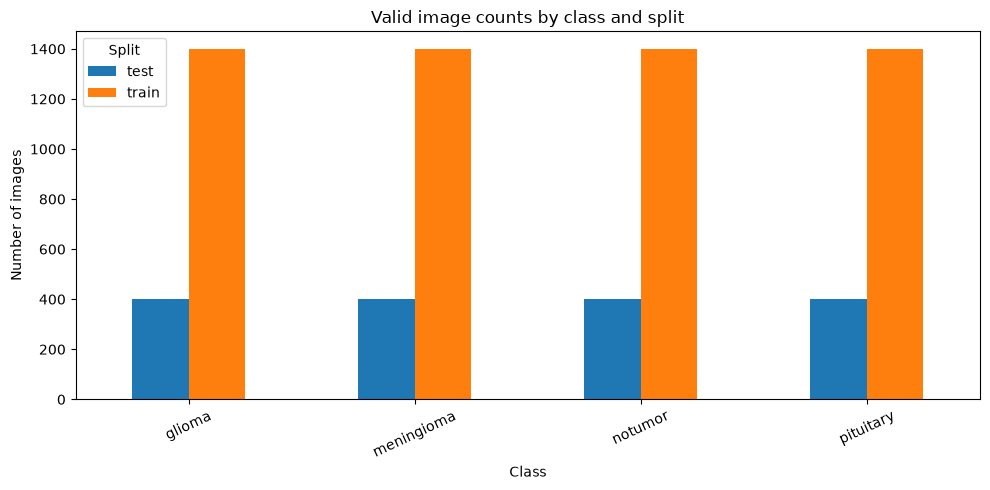

Valid images by split:


,valid_images
split,
test,1600
train,5600


In [6]:
counts = (valid_df.groupby(["split", "class_name"]).size()
          .rename("count").reset_index())
pivot_counts = counts.pivot(index="class_name", columns="split", values="count").fillna(0)

ax = pivot_counts.plot(kind="bar", figsize=(10, 5), rot=25)
ax.set_title("Valid image counts by class and split")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.legend(title="Split")
plt.tight_layout()
plt.savefig(VIS_DIR / "class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

split_sizes = valid_df.groupby("split").size()
print("Valid images by split:")
display(split_sizes.rename("valid_images").to_frame())

## 5. Visual inspection of examples

Inspect examples from every class, including any unexpected rotations, borders, labels or watermarks. Images are shown from the files on disk; this cell uses a fixed seed for reproducibility.

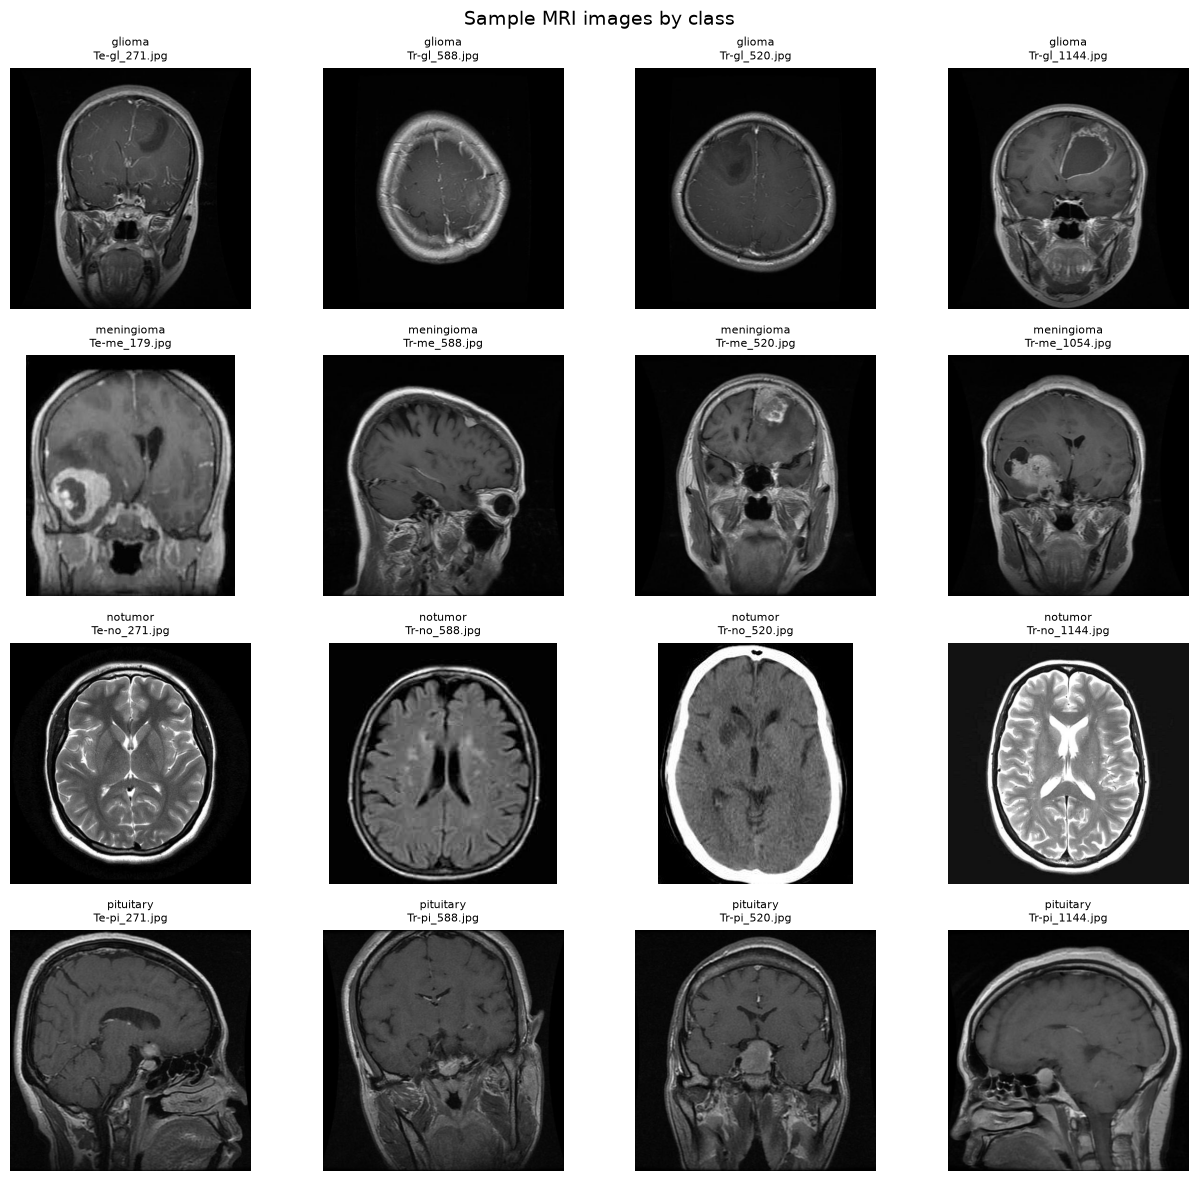

In [7]:
def show_class_samples(frame: pd.DataFrame, samples_per_class: int = 4, seed: int = SEED):
    class_names = sorted(frame["class_name"].unique())
    nrows, ncols = len(class_names), samples_per_class
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.0 * nrows), squeeze=False)
    rng = np.random.default_rng(seed)
    for r, class_name in enumerate(class_names):
        subset = frame[frame["class_name"] == class_name]
        selected = subset.sample(n=min(samples_per_class, len(subset)), random_state=seed)
        for c in range(ncols):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(selected):
                row = selected.iloc[c]
                try:
                    with Image.open(row["absolute_path"]) as im:
                        ax.imshow(im.convert("RGB"))
                    ax.set_title(f"{class_name}\n{row['filename'][:24]}", fontsize=8)
                except Exception as exc:
                    ax.set_title(f"Could not open\n{type(exc).__name__}", fontsize=8)
    fig.suptitle("Sample MRI images by class", fontsize=14)
    plt.tight_layout()
    plt.savefig(VIS_DIR / "sample_images_by_class.png", dpi=160, bbox_inches="tight")
    plt.show()

show_class_samples(valid_df, samples_per_class=4)

## 6. Image dimensions, color modes and file formats

Pretrained models usually require a consistent input size, but first inspect the original distribution. Convert images to RGB in the data loader even if most files are grayscale; this keeps the pipeline compatible with ImageNet-pretrained models.

Image dimension summary:


,width,height,aspect_ratio,megapixels
count,7200.000,7200.000,7200.000,7200.000
mean,453.303,456.899,0.990,0.223
std,130.049,124.402,0.092,0.116
min,150.000,167.000,0.645,0.029
25%,442.000,449.000,1.000,0.201
50%,512.000,512.000,1.000,0.262
75%,512.000,512.000,1.000,0.262
max,1375.000,1446.000,1.786,1.988


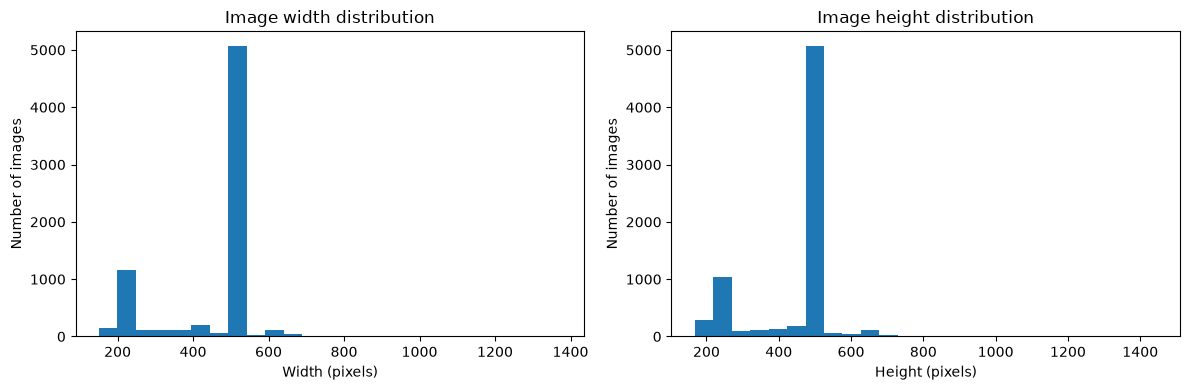

Color mode counts:


,count
mode,
RGB,4129
L,3067
RGBA,3
P,1


File format counts:


,count
format,
JPEG,7196
PNG,4


In [8]:
valid_df["width"] = valid_df["width"].astype(int)
valid_df["height"] = valid_df["height"].astype(int)
valid_df["aspect_ratio"] = valid_df["width"] / valid_df["height"]
valid_df["megapixels"] = (valid_df["width"] * valid_df["height"]) / 1_000_000

print("Image dimension summary:")
display(valid_df[["width", "height", "aspect_ratio", "megapixels"]].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(valid_df["width"], bins=25)
axes[0].set_title("Image width distribution")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Number of images")
axes[1].hist(valid_df["height"], bins=25)
axes[1].set_title("Image height distribution")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Number of images")
plt.tight_layout()
plt.savefig(VIS_DIR / "image_dimensions.png", dpi=160, bbox_inches="tight")
plt.show()

print("Color mode counts:")
display(valid_df["mode"].value_counts(dropna=False).rename_axis("mode").to_frame("count"))
print("File format counts:")
display(valid_df["image_format"].value_counts(dropna=False).rename_axis("format").to_frame("count"))

## 7. Exact duplicate audit using SHA-256

Files with the same SHA-256 hash have identical file bytes. This is strong evidence of exact file duplication. The audit checks duplicates within each split and across the training/testing folders.

In [9]:
hashed_df = valid_df[valid_df["sha256"].notna()].copy()
exact_group_sizes = hashed_df.groupby("sha256").size()
duplicate_hashes = exact_group_sizes[exact_group_sizes > 1].index
exact_duplicate_rows = hashed_df[hashed_df["sha256"].isin(duplicate_hashes)].sort_values("sha256")

print("Unique valid files by SHA-256:", hashed_df["sha256"].nunique())
print("Exact-duplicate hash groups:", len(duplicate_hashes))
print("Rows belonging to an exact-duplicate group:", len(exact_duplicate_rows))

if len(exact_duplicate_rows):
    display(exact_duplicate_rows[["split", "class_name", "relative_path", "sha256"]].head(50))
    exact_duplicate_rows.drop(columns=["absolute_path"]).to_csv(
        RESULTS_DIR / "exact_duplicate_groups.csv", index=False
    )
    print("Saved:", RESULTS_DIR / "exact_duplicate_groups.csv")
else:
    print("No exact duplicate files detected.")

# Cross-split exact duplicates: same hash observed in both train and test.
split_counts_per_hash = hashed_df.groupby("sha256")["split"].nunique()
cross_split_exact_hashes = split_counts_per_hash[split_counts_per_hash > 1].index
cross_split_exact = hashed_df[hashed_df["sha256"].isin(cross_split_exact_hashes)].sort_values("sha256")
print("\nExact-duplicate hashes present in both train and test:", len(cross_split_exact_hashes))
if not cross_split_exact.empty:
    display(cross_split_exact[["split", "class_name", "relative_path", "sha256"]].head(100))
    cross_split_exact.drop(columns=["absolute_path"]).to_csv(
        RESULTS_DIR / "cross_split_exact_duplicates.csv", index=False
    )
    print("Saved:", RESULTS_DIR / "cross_split_exact_duplicates.csv")

# Check whether byte-identical files are assigned conflicting class labels.
label_count_per_hash = hashed_df.groupby("sha256")["class_name"].nunique()
conflicting_hashes = label_count_per_hash[label_count_per_hash > 1].index
conflicting_exact = hashed_df[hashed_df["sha256"].isin(conflicting_hashes)].sort_values("sha256")
print("Exact-hash groups with conflicting class labels:", len(conflicting_hashes))
if not conflicting_exact.empty:
    display(conflicting_exact[["split", "class_name", "relative_path", "sha256"]].head(50))

Unique valid files by SHA-256: 7013
Exact-duplicate hash groups: 153
Rows belonging to an exact-duplicate group: 340


,split,class_name,relative_path,sha256
5921,test,glioma,Testing/glioma/Te-gl_389.jpg,04aa41d8514362877d7f8fd81e543bc8584e4a6ba1ac025c2f37515f32abd9b0
5845,test,glioma,Testing/glioma/Te-gl_32.jpg,04aa41d8514362877d7f8fd81e543bc8584e4a6ba1ac025c2f37515f32abd9b0
2853,train,notumor,Training/notumor/Tr-no_1046.jpg,05ec18666c6b751b8845a93824ea25c9bb251606b71f76c0c3875d69e973f72d
3595,train,notumor,Training/notumor/Tr-no_454.jpg,05ec18666c6b751b8845a93824ea25c9bb251606b71f76c0c3875d69e973f72d
2282,train,meningioma,Training/meningioma/Tr-me_532.jpg,089a7ad8107e9ef50fc7c35e7407b18fcda170be3707749807a059a5cb46b3a8
1497,train,meningioma,Training/meningioma/Tr-aug-me_97.jpg,089a7ad8107e9ef50fc7c35e7407b18fcda170be3707749807a059a5cb46b3a8
2619,train,meningioma,Training/meningioma/Tr-me_836.jpg,09b9031e30e757eb6e648686f0ca412357e86895ebbc52d300d2d0a9305fd417
1615,train,meningioma,Training/meningioma/Tr-me_1101.jpg,09b9031e30e757eb6e648686f0ca412357e86895ebbc52d300d2d0a9305fd417
2677,train,meningioma,Training/meningioma/Tr-me_889.jpg,0f673459b5dba7f9dab9a6a32309e2c89ddf4bb9b799d3350f56c33e8cc8b2d3
1488,train,meningioma,Training/meningioma/Tr-aug-me_89.jpg,0f673459b5dba7f9dab9a6a32309e2c89ddf4bb9b799d3350f56c33e8cc8b2d3


Saved: D:\computer vision\Brain-MRI-Classification\results\exact_duplicate_groups.csv

Exact-duplicate hashes present in both train and test: 0
Exact-hash groups with conflicting class labels: 0


## 8. Near-duplicate audit using perceptual hashes (optional but recommended)

A perceptual hash (pHash) summarizes image appearance rather than file bytes, so it can flag resized or recompressed variants that SHA-256 will not catch. It is a **screening tool, not ground truth**. Similar MRI slices may be flagged even when they are not duplicates; inspect candidate pairs before drawing conclusions.

This cell compares valid training images against valid testing images with a vectorized Hamming-distance computation. For this dataset size it should be manageable, but it can take time. Install `ImageHash` if needed (`pip install ImageHash`). Set `RUN_PERCEPTUAL_AUDIT = False` to skip it.

In [11]:
RUN_PERCEPTUAL_AUDIT = False
PHASH_DISTANCE_THRESHOLD = 6  # Lower = stricter. Review candidates visually.
PHASH_CACHE = RESULTS_DIR / "perceptual_hashes.csv"

if RUN_PERCEPTUAL_AUDIT:
    try:
        import imagehash
    except ImportError as exc:
        raise ImportError(
            "The optional near-duplicate audit requires ImageHash. Run `pip install ImageHash` "
            "or set RUN_PERCEPTUAL_AUDIT = False."
        ) from exc

    if PHASH_CACHE.exists():
        phash_df = pd.read_csv(PHASH_CACHE)
        cached_paths = set(phash_df["relative_path"].astype(str))
        expected_paths = set(valid_df["relative_path"].astype(str))
        if cached_paths != expected_paths:
            print("Perceptual-hash cache does not match the current inventory; recomputing hashes.")
            phash_df = None
    else:
        phash_df = None

    if phash_df is None:
        hash_records = []
        for i, row in enumerate(valid_df.itertuples(index=False), start=1):
            try:
                with Image.open(row.absolute_path) as im:
                    p_hash = str(imagehash.phash(im.convert("RGB")))
                hash_records.append({
                    "relative_path": row.relative_path,
                    "split": row.split,
                    "class_name": row.class_name,
                    "filename": row.filename,
                    "sha256": row.sha256,
                    "phash_hex": p_hash,
                    "phash_int": int(p_hash, 16),
                    "absolute_path": row.absolute_path,
                })
            except Exception as exc:
                warnings.warn(f"Could not compute pHash for {row.relative_path}: {exc}")
            if i % 1000 == 0:
                print(f"  computed perceptual hashes for {i:,}/{len(valid_df):,}")
        phash_df = pd.DataFrame(hash_records)
        phash_df.to_csv(PHASH_CACHE, index=False)
        print("Saved perceptual hashes:", PHASH_CACHE)

    train_hashes = phash_df[phash_df["split"] == "train"].reset_index(drop=True)
    test_hashes = phash_df[phash_df["split"] == "test"].reset_index(drop=True)
    print(f"Comparing {len(train_hashes):,} training images with {len(test_hashes):,} testing images...")

    # Lookup table for the number of set bits in one byte; pHash strings are 64-bit values.
    popcount8 = np.array([int(x).bit_count() for x in range(256)], dtype=np.uint8)
    train_ints = train_hashes["phash_int"].astype("uint64").to_numpy()
    test_ints = test_hashes["phash_int"].astype("uint64").to_numpy()
    train_sha = train_hashes["sha256"].fillna("").to_numpy()
    test_sha = test_hashes["sha256"].fillna("").to_numpy()
    candidate_records = []
    chunk_size = 128

    for start in range(0, len(train_hashes), chunk_size):
        stop = min(start + chunk_size, len(train_hashes))
        xor = np.bitwise_xor(train_ints[start:stop, None], test_ints[None, :])
        distance = np.zeros(xor.shape, dtype=np.uint8)
        for shift in range(0, 64, 8):
            byte = ((xor >> np.uint64(shift)) & np.uint64(255)).astype(np.uint8)
            distance += popcount8[byte]
        near_i, near_j = np.where(distance <= PHASH_DISTANCE_THRESHOLD)
        for local_i, j in zip(near_i.tolist(), near_j.tolist()):
            i = start + local_i
            # Exact duplicates are already captured by SHA-256; keep this file for non-identical candidates.
            if train_sha[i] == test_sha[j]:
                continue
            candidate_records.append({
                "train_path": train_hashes.iloc[i]["relative_path"],
                "train_class": train_hashes.iloc[i]["class_name"],
                "test_path": test_hashes.iloc[j]["relative_path"],
                "test_class": test_hashes.iloc[j]["class_name"],
                "phash_hamming_distance": int(distance[local_i, j]),
                "same_class_label": bool(train_hashes.iloc[i]["class_name"] == test_hashes.iloc[j]["class_name"]),
                "train_absolute_path": train_hashes.iloc[i]["absolute_path"],
                "test_absolute_path": test_hashes.iloc[j]["absolute_path"],
            })
        if stop % 1024 == 0 or stop == len(train_hashes):
            print(f"  compared {stop:,}/{len(train_hashes):,} training images")

    near_duplicate_candidates = pd.DataFrame(candidate_records)
    if near_duplicate_candidates.empty:
        print(f"No non-identical train/test pairs found within pHash distance {PHASH_DISTANCE_THRESHOLD}.")
    else:
        near_duplicate_candidates = near_duplicate_candidates.sort_values(
            ["phash_hamming_distance", "train_path", "test_path"]
        ).reset_index(drop=True)
        export_candidates = near_duplicate_candidates.drop(
            columns=["train_absolute_path", "test_absolute_path"]
        )
        export_candidates.to_csv(RESULTS_DIR / "cross_split_near_duplicate_candidates.csv", index=False)
        print("Candidate train/test pairs:", len(near_duplicate_candidates))
        print("Saved:", RESULTS_DIR / "cross_split_near_duplicate_candidates.csv")
        display(export_candidates.head(30))
else:
    print("Skipped perceptual-hash audit. Set RUN_PERCEPTUAL_AUDIT = True to run it.")

Skipped perceptual-hash audit. Set RUN_PERCEPTUAL_AUDIT = True to run it.


## 9. Visual review of nearest near-duplicate candidates

Review the lowest-distance candidates side-by-side. This helps distinguish true duplicate/near-duplicate cases from merely similar scans. Do not automatically delete or reassign images based on pHash alone.

In [12]:
if RUN_PERCEPTUAL_AUDIT and "near_duplicate_candidates" in globals() and not near_duplicate_candidates.empty:
    n_show = min(12, len(near_duplicate_candidates))
    fig, axes = plt.subplots(n_show, 2, figsize=(8, max(3, 2.4 * n_show)), squeeze=False)
    for r in range(n_show):
        row = near_duplicate_candidates.iloc[r]
        for c, path_col in enumerate(["train_absolute_path", "test_absolute_path"]):
            ax = axes[r, c]
            try:
                with Image.open(row[path_col]) as im:
                    ax.imshow(im.convert("RGB"), cmap="gray")
                label = row["train_class"] if c == 0 else row["test_class"]
                ax.set_title(f"{'TRAIN' if c == 0 else 'TEST'} | {label} | {row['phash_hamming_distance']}", fontsize=8)
            except Exception as exc:
                ax.set_title(f"Cannot open image: {exc}", fontsize=7)
            ax.axis("off")
    plt.suptitle("Lowest-distance pHash candidates — manual review required", y=1.002)
    plt.tight_layout()
    plt.savefig(VIS_DIR / "near_duplicate_candidate_review.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("No near-duplicate candidates available to visualize.")

No near-duplicate candidates available to visualize.


## 10. Image dimensions by class and split

These plots help identify unusual image sizes or differences in image acquisition/preprocessing between folders. They do not establish biological or clinical differences.

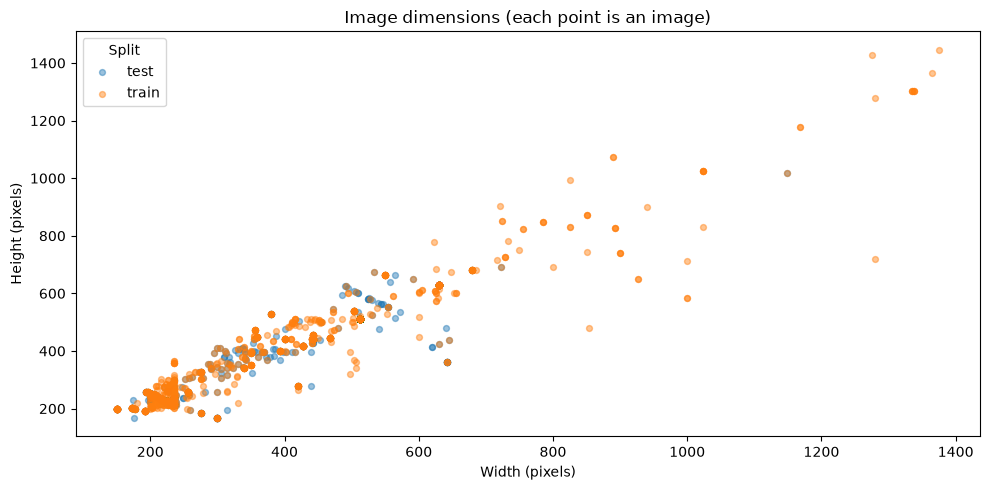

Image modes by split:


mode,L,P,RGB,RGBA
split,,,,
test,709,0,891,0
train,2358,1,3238,3


Image formats by split:


image_format,JPEG,PNG
split,,
test,1600,0
train,5596,4


In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
for split_name, group in valid_df.groupby("split"):
    ax.scatter(group["width"], group["height"], alpha=0.45, s=18, label=split_name)
ax.set_title("Image dimensions (each point is an image)")
ax.set_xlabel("Width (pixels)")
ax.set_ylabel("Height (pixels)")
ax.legend(title="Split")
plt.tight_layout()
plt.savefig(VIS_DIR / "width_vs_height.png", dpi=160, bbox_inches="tight")
plt.show()

mode_summary = pd.crosstab(valid_df["split"], valid_df["mode"])
format_summary = pd.crosstab(valid_df["split"], valid_df["image_format"])
print("Image modes by split:")
display(mode_summary)
print("Image formats by split:")
display(format_summary)

## 11. Export an audit summary

This produces a compact JSON file to retain with the experiment results. Review and edit the generated report before publishing it, especially any near-duplicate counts that require visual interpretation.

In [14]:
class_counts_json = {
    split: {str(label): int(count) for label, count in group.groupby("class_name").size().items()}
    for split, group in valid_df.groupby("split")
}

summary_report = {
    "dataset_root_relative_to_project": str(DATASET_ROOT.relative_to(PROJECT_ROOT)) if DATASET_ROOT.is_relative_to(PROJECT_ROOT) else str(DATASET_ROOT),
    "total_image_files": int(len(images_df)),
    "valid_images": int(images_df["is_valid"].sum()),
    "invalid_images": int((~images_df["is_valid"]).sum()),
    "class_names": sorted(valid_df["class_name"].unique().tolist()),
    "valid_counts_by_split_and_class": class_counts_json,
    "unique_sha256_hashes": int(hashed_df["sha256"].nunique()),
    "exact_duplicate_hash_groups": int(len(duplicate_hashes)),
    "cross_split_exact_duplicate_hash_groups": int(len(cross_split_exact_hashes)),
    "exact_hash_groups_with_conflicting_labels": int(len(conflicting_hashes)),
    "perceptual_audit_run": bool(RUN_PERCEPTUAL_AUDIT),
    "phash_distance_threshold": int(PHASH_DISTANCE_THRESHOLD) if RUN_PERCEPTUAL_AUDIT else None,
    "cross_split_nonidentical_phash_candidate_pairs": int(len(near_duplicate_candidates)) if RUN_PERCEPTUAL_AUDIT and "near_duplicate_candidates" in globals() else None,
    "notes": [
        "pHash matches are candidates and must be visually reviewed.",
        "No reliable patient identifiers are assumed to be available.",
        "This audit does not establish patient-level independence or clinical validity."
    ]
}

summary_path = RESULTS_DIR / "data_audit_summary.json"
summary_path.write_text(json.dumps(summary_report, indent=2), encoding="utf-8")
print(json.dumps(summary_report, indent=2))
print("\nSaved:", summary_path)

{
  "dataset_root_relative_to_project": "data\\brain-tumor-mri-dataset",
  "total_image_files": 7200,
  "valid_images": 7200,
  "invalid_images": 0,
  "class_names": [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
  ],
  "valid_counts_by_split_and_class": {
    "test": {
      "glioma": 400,
      "meningioma": 400,
      "notumor": 400,
      "pituitary": 400
    },
    "train": {
      "glioma": 1400,
      "meningioma": 1400,
      "notumor": 1400,
      "pituitary": 1400
    }
  },
  "unique_sha256_hashes": 7013,
  "exact_duplicate_hash_groups": 153,
  "cross_split_exact_duplicate_hash_groups": 0,
  "exact_hash_groups_with_conflicting_labels": 0,
  "perceptual_audit_run": false,
  "phash_distance_threshold": null,
  "cross_split_nonidentical_phash_candidate_pairs": null,
  "notes": [
    "pHash matches are candidates and must be visually reviewed.",
    "No reliable patient identifiers are assumed to be available.",
    "This audit does not establish patient-level 

## 12. Decisions before model training

Review every item below. If an issue is found, document how it was handled in the README; do not silently change the dataset.

- [ ] The dataset was downloaded from a documented source and the final file counts were recorded.
- [ ] All unreadable images were inspected and excluded or fixed transparently.
- [ ] Class folders match between the training and testing splits.
- [ ] Class imbalance has been quantified.
- [ ] Exact cross-split duplicates were recorded.
- [ ] Near-duplicate candidates were visually reviewed; pHash was not treated as ground truth.
- [ ] The official test set will not be used for hyperparameter tuning or checkpoint selection.
- [ ] A validation set will be created from training data, with known duplicate groups kept together where practical.
- [ ] Image augmentation will be applied only to training data.
- [ ] Reports will describe this as an educational classification benchmark, not a clinical diagnostic system.

### Next notebook

Proceed to `02_custom_cnn.ipynb`. Reuse the class names and image inventory, but implement the training/validation split and data loaders in reusable functions under `src/`. Keep the test-set audit separate from model selection.